In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [2]:
df = pd.read_excel("Cleaned_DataV4.xlsx")

In [ ]:
df.head()

In [8]:
df_analysis = df.copy()

In [9]:
# Loại các trường hợp không xác định ở 1 trong 2 cột
temp = df_analysis[
    (df_analysis["HKTT_Tỉnh"] != "Không xác định") &
    (df_analysis["Tên tỉnh THPT"] != "Không xác định")
].copy()

total = len(temp)

# 1. HKTT_Tỉnh có giống Tên tỉnh THPT không?
same = temp["HKTT_Tỉnh"] == temp["Tên tỉnh THPT"]

print(f"Tổng số SV có đủ 2 thông tin: {total:,}")
print(
    f"HKTT_Tỉnh = Tên tỉnh THPT: "
    f"{same.sum():,}/{total:,} ({same.mean()*100:.1f}%)"
)


# 2. Cả HKTT và tỉnh THPT đều là TP.HCM
both_hcm = (
    (temp["HKTT_Tỉnh"] == "Hồ Chí Minh") &
    (temp["Tên tỉnh THPT"] == "Hồ Chí Minh")
)

print(
    f"\nCả HKTT và tỉnh THPT đều TP.HCM: "
    f"{both_hcm.sum():,}/{total:,} ({both_hcm.mean()*100:.1f}%)"
)


# 3. Trong số SV học THPT tại TP.HCM,
# bao nhiêu người cũng có HKTT tại TP.HCM?
thpt_hcm = temp[temp["Tên tỉnh THPT"] == "Hồ Chí Minh"]

hktt_hcm_given_thpt_hcm = (
    thpt_hcm["HKTT_Tỉnh"] == "Hồ Chí Minh"
)

print(
    f"\nSV có tỉnh THPT = TP.HCM: {len(thpt_hcm):,}"
)

print(
    f"Trong nhóm này, HKTT cũng = TP.HCM: "
    f"{hktt_hcm_given_thpt_hcm.sum():,}/{len(thpt_hcm):,} "
    f"({hktt_hcm_given_thpt_hcm.mean()*100:.1f}%)"
)

Tổng số SV có đủ 2 thông tin: 34,166
HKTT_Tỉnh = Tên tỉnh THPT: 25,139/34,166 (73.6%)

Cả HKTT và tỉnh THPT đều TP.HCM: 12,192/34,166 (35.7%)

SV có tỉnh THPT = TP.HCM: 12,439
Trong nhóm này, HKTT cũng = TP.HCM: 12,192/12,439 (98.0%)


In [10]:
hktt_hcm = temp[temp["HKTT_Tỉnh"] == "Hồ Chí Minh"]

thpt_hcm_given_hktt_hcm = (
    hktt_hcm["Tên tỉnh THPT"] == "Hồ Chí Minh"
)

print(
    f"SV có HKTT = TP.HCM: {len(hktt_hcm):,}"
)

print(
    f"Trong nhóm này, tỉnh THPT cũng = TP.HCM: "
    f"{thpt_hcm_given_hktt_hcm.sum():,}/{len(hktt_hcm):,} "
    f"({thpt_hcm_given_hktt_hcm.mean()*100:.1f}%)"
)

SV có HKTT = TP.HCM: 18,098
Trong nhóm này, tỉnh THPT cũng = TP.HCM: 12,192/18,098 (67.4%)


In [11]:
df_hcm = df_analysis[
    (df_analysis["Tên tỉnh THPT"] == "Hồ Chí Minh") &
    (df_analysis["HKTT_Tỉnh"] == "Hồ Chí Minh")
].copy()

print(f"Tổng số SV: {len(df_hcm):,}")

print("Số giá trị HKTT_Huyện unique:",
      df_hcm["HKTT_Huyện"].nunique())

print(
    df_hcm["HKTT_Huyện"]
    .value_counts(dropna=False)
    .to_string()
)

Tổng số SV: 12,192
Số giá trị HKTT_Huyện unique: 161
HKTT_Huyện
Quận Tân Bình             1838
Quận Tân Phú              1094
Huyện Củ Chi               949
Quận Bình Tân              859
Quận 12                    770
Quận Gò Vấp                736
Huyện Hóc Môn              669
Quận Phú Nhuận             619
Quận 11                    536
Quận 3                     502
Quận Bình Thạnh            466
Quận 10                    403
Huyện Bình Chánh           400
Quận 7                     163
Không xác định             153
Quận 6                     146
Quận 8                     141
Quận 1                     116
Thành phố Thủ Đức           97
Quận 5                      78
Quận 4                      77
Xã Củ Chi                   50
Phường Bảy Hiền           43
Xã Đông Thạnh               34
Phường Bình Hưng Hòa        33
Huyện Cần Giờ               32
Xã Bà Điểm                  30
Phường Gia Định             29
Phường Tân Hòa             29
Xã Tân An Hội               28
Xã Thá

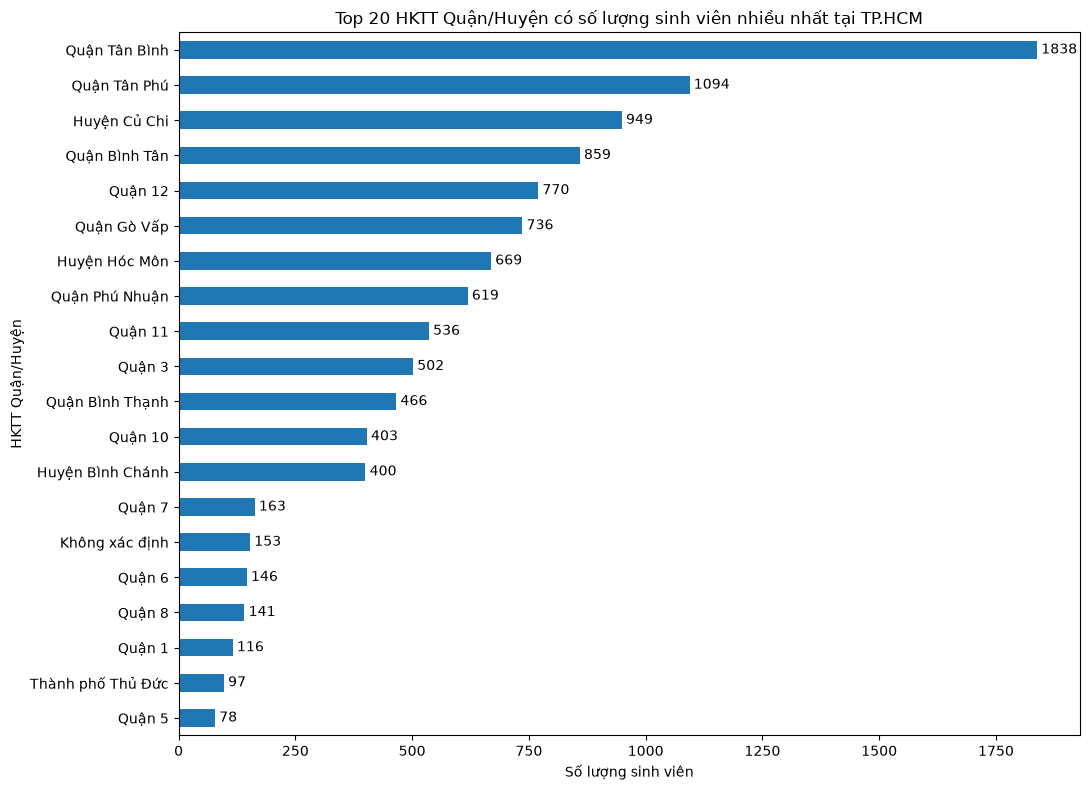

In [12]:
# Đếm số sinh viên theo HKTT Quận/Huyện
district_counts = (
    df_hcm["HKTT_Huyện"]
    .value_counts()
    .head(20)
    .sort_values()
)

plt.figure(figsize=(11, 8))

ax = district_counts.plot(
    kind="barh"
)

plt.title("Top 20 HKTT Quận/Huyện có số lượng sinh viên nhiều nhất tại TP.HCM")
plt.xlabel("Số lượng sinh viên")
plt.ylabel("HKTT Quận/Huyện")

# Hiển thị số lượng ở cuối mỗi cột
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

In [12]:
for year in sorted(df_hcm["Khóa học"].unique()):
    temp_year = df_hcm[df_hcm["Khóa học"] == year]

    print(f"\n===== {year} =====")
    print(f"Số SV: {len(temp_year):,}")
    print(f"Unique HKTT_Huyện: {temp_year['HKTT_Huyện'].nunique()}")

    print(
        temp_year["HKTT_Huyện"]
        .value_counts()
        .head(20)
        .to_string()
    )


===== 2020 =====
Số SV: 2,281
Unique HKTT_Huyện: 25
HKTT_Huyện
Quận Tân Bình       389
Huyện Củ Chi        232
Quận Tân Phú        212
Quận Bình Tân       170
Quận Gò Vấp         160
Quận 12             148
Quận 7              128
Huyện Hóc Môn       115
Quận Phú Nhuận      113
Quận 11             104
Quận Bình Thạnh      99
Quận 3               86
Quận 10              85
Huyện Bình Chánh     82
Quận 8               32
Quận 6               30
Quận 4               24
Quận 1               21
Quận 5               15
Huyện Nhà Bè         11

===== 2021 =====
Số SV: 2,094
Unique HKTT_Huyện: 25
HKTT_Huyện
Quận Tân Bình        356
Quận Tân Phú         215
Quận Bình Tân        193
Quận 12              172
Huyện Củ Chi         167
Quận Gò Vấp          141
Huyện Hóc Môn        141
Huyện Bình Chánh     103
Quận 3                97
Quận Phú Nhuận        93
Quận 11               90
Quận Bình Thạnh       79
Quận 10               77
Quận 8                36
Quận 6                30
Quận 1           

In [13]:
#2020 - 2024

In [14]:
hcm_district = df_hcm[
    df_hcm["Khóa học"].between(2020, 2024)
].copy()

# bỏ Không xác định
hcm_district = hcm_district[
    hcm_district["HKTT_Huyện"] != "Không xác định"
]

print(f"Số SV dùng để phân tích: {len(hcm_district):,}")

Số SV dùng để phân tích: 9,806


In [15]:
district_summary = (
    hcm_district["HKTT_Huyện"]
    .value_counts()
    .rename_axis("Quận/Huyện")
    .reset_index(name="Số lượng")
)

district_summary["Tỷ lệ (%)"] = (
    district_summary["Số lượng"]
    / district_summary["Số lượng"].sum()
    * 100
)

district_summary["Tỷ lệ (%)"] = (
    district_summary["Tỷ lệ (%)"].round(1)
)

district_summary.head(20)

,Quận/Huyện,Số lượng,Tỷ lệ (%)
0,Quận Tân Bình,1699,17.3
1,Quận Tân Phú,973,9.9
2,Huyện Củ Chi,859,8.8
3,Quận Bình Tân,783,8.0
4,Quận 12,716,7.3
5,Quận Gò Vấp,677,6.9
6,Huyện Hóc Môn,612,6.2
7,Quận Phú Nhuận,562,5.7
8,Quận 11,493,5.0
9,Quận 3,450,4.6


In [16]:
district_year = pd.crosstab(
    hcm_district["HKTT_Huyện"],
    hcm_district["Khóa học"]
)

district_year_pct = (
    district_year
    .div(district_year.sum(axis=0), axis=1)
    * 100
)

district_year_pct.round(1)

Khóa học,2020,2021,2022,2023,2024
HKTT_Huyện,,,,,
Huyện Bình Chánh,3.6,4.9,3.9,3.1,2.5
Huyện Cần Giờ,0.1,0.3,0.4,0.4,0.1
Huyện Củ Chi,10.2,8.0,9.3,8.1,7.8
Huyện Hóc Môn,5.1,6.7,5.6,5.7,8.5
Huyện Nhà Bè,0.5,0.2,0.2,0.1,0.1
Phường Bình Cơ,0.0,0.0,0.0,0.0,0.1
Quận 1,0.9,1.1,1.3,1.3,0.7
Quận 10,3.7,3.7,4.1,3.4,3.8
Quận 11,4.6,4.3,5.3,5.7,5.6


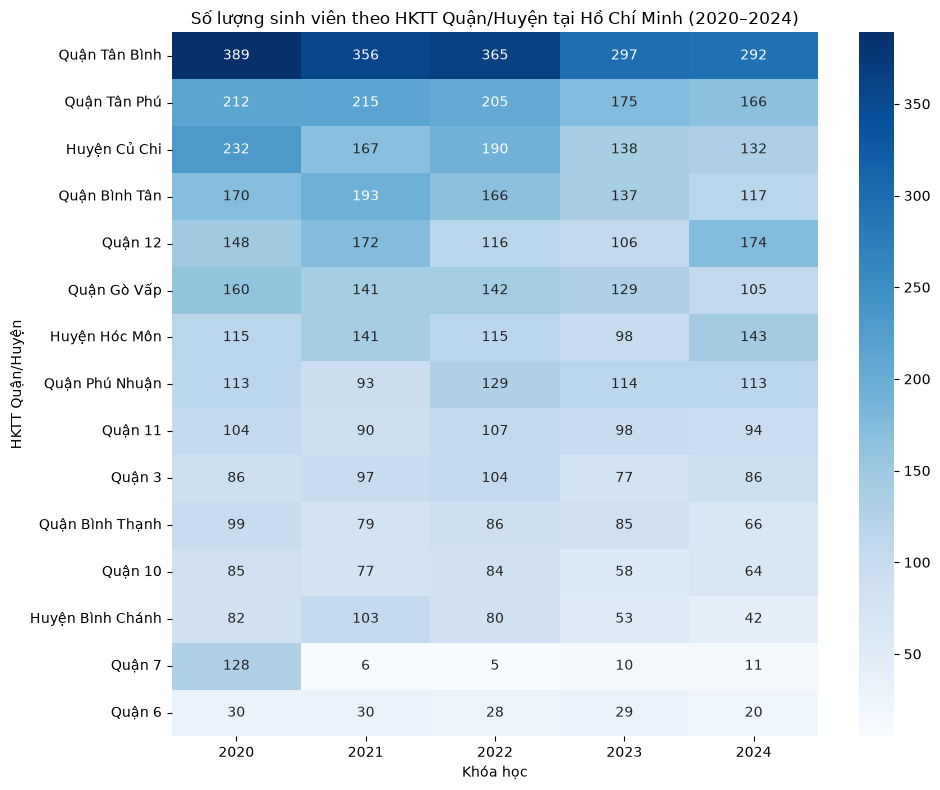

In [18]:
# Bảng số lượng Quận/Huyện × Khóa học
district_year = pd.crosstab(
    hcm_district["HKTT_Huyện"],
    hcm_district["Khóa học"]
)

# Lấy Top 15 quận/huyện có tổng số SV cao nhất
top15_district = (
    district_year.sum(axis=1)
    .sort_values(ascending=False)
    .head(15)
    .index
)

heatmap_count = district_year.loc[top15_district]

# Vẽ heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    heatmap_count,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Số lượng sinh viên theo HKTT Quận/Huyện tại Hồ Chí Minh (2020–2024)"
)
plt.xlabel("Khóa học")
plt.ylabel("HKTT Quận/Huyện")

plt.tight_layout()
plt.show()

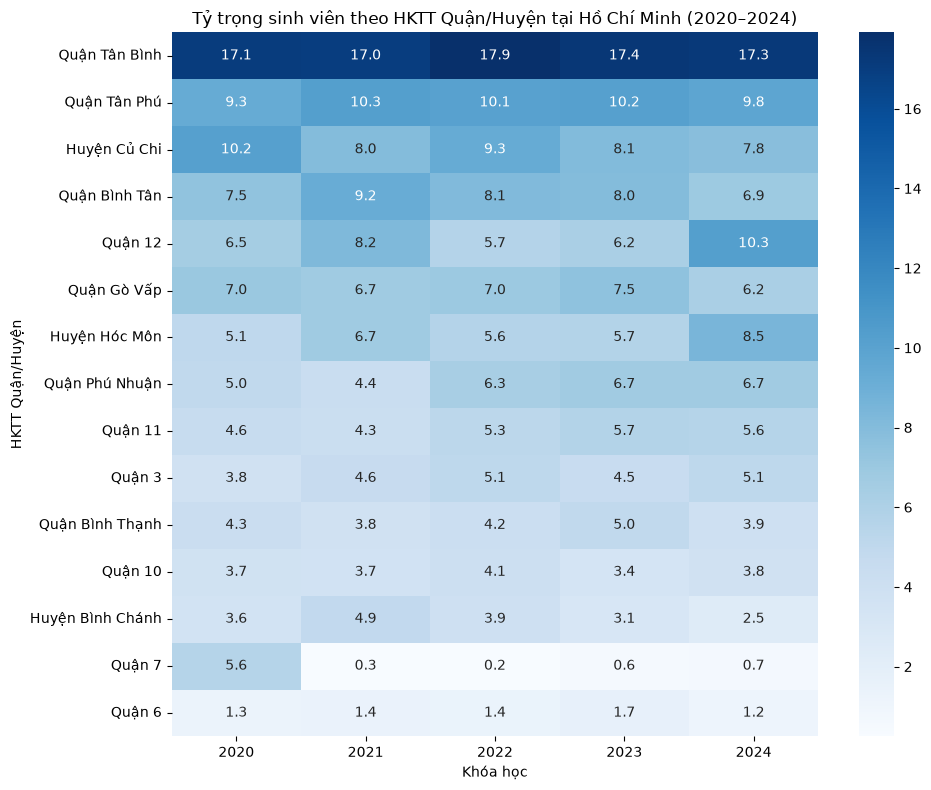

In [17]:
top15_district = (
    hcm_district["HKTT_Huyện"]
    .value_counts()
    .head(15)
    .index
)

heatmap_data = district_year_pct.loc[top15_district]

plt.figure(figsize=(10, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title(
    "Tỷ trọng sinh viên theo HKTT Quận/Huyện tại Hồ Chí Minh (2020–2024)"
)
plt.xlabel("Khóa học")
plt.ylabel("HKTT Quận/Huyện")

plt.tight_layout()
plt.show()

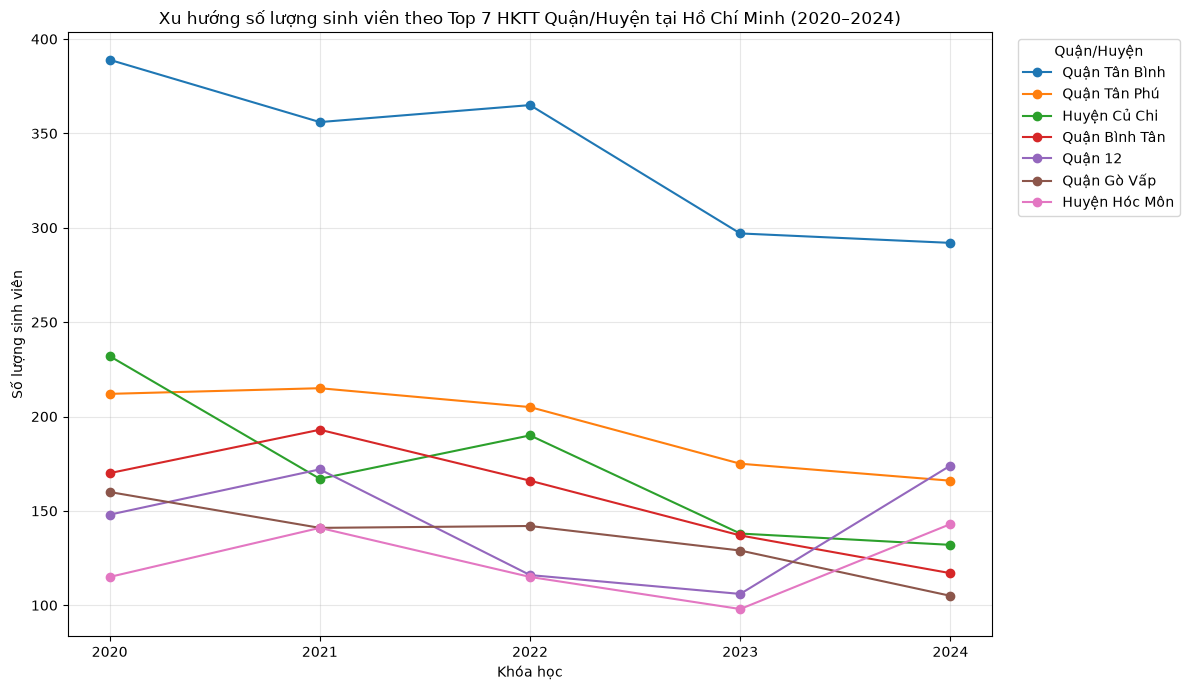

In [19]:
# Top 7 quận/huyện theo tổng số SV 2020–2024
top7_district = (
    district_year.sum(axis=1)
    .sort_values(ascending=False)
    .head(7)
    .index
)

# Chuyển bảng để năm nằm trên trục X
top7_trend = (
    district_year
    .loc[top7_district]
    .T
)

# Vẽ line chart
plt.figure(figsize=(12, 7))

for district in top7_trend.columns:
    plt.plot(
        top7_trend.index,
        top7_trend[district],
        marker="o",
        label=district
    )

plt.title(
    "Xu hướng số lượng sinh viên theo Top 7 HKTT Quận/Huyện tại Hồ Chí Minh (2020–2024)"
)
plt.xlabel("Khóa học")
plt.ylabel("Số lượng sinh viên")

plt.xticks(top7_trend.index)
plt.legend(title="Quận/Huyện", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

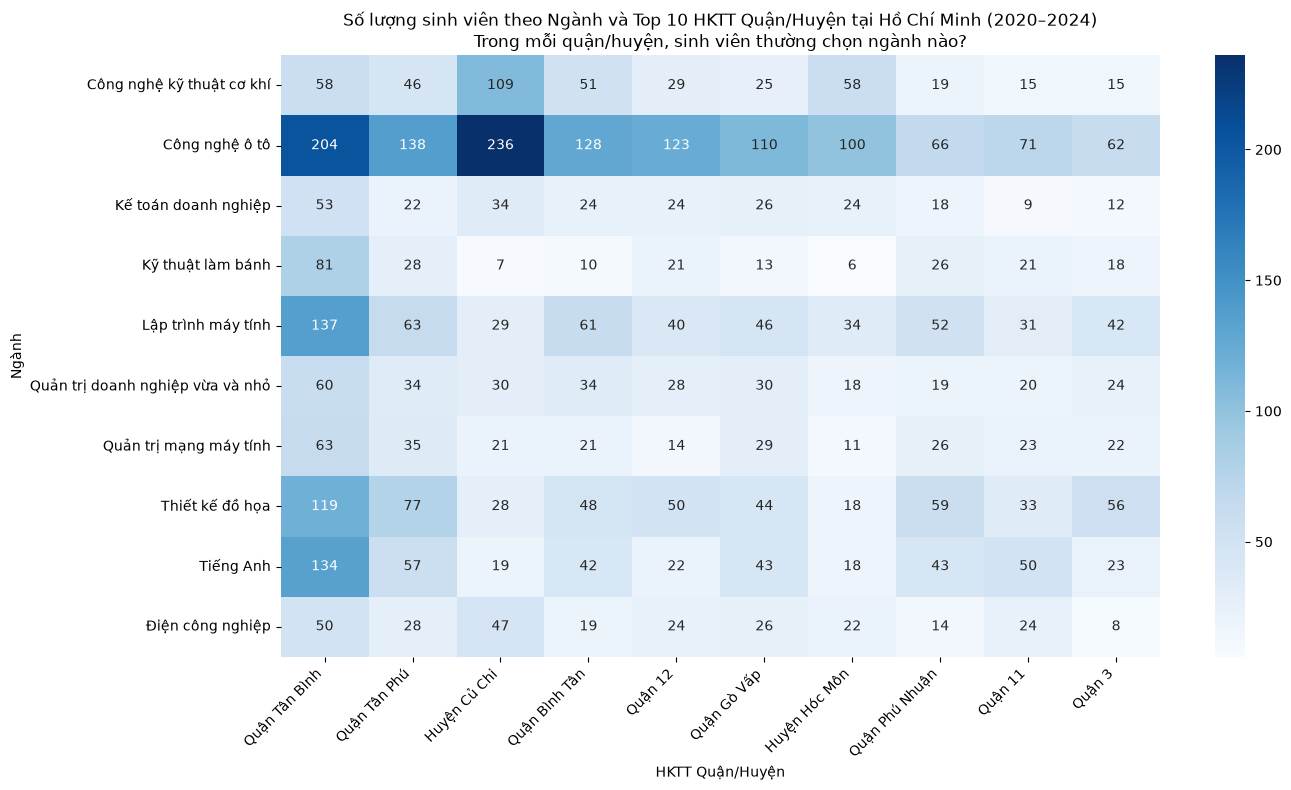

In [53]:
# Top 10 quận/huyện
top10_district = (
    hcm_district["HKTT_Huyện"]
    .value_counts()
    .head(10)
    .index
)

# Top 10 ngành
top10_major = (
    hcm_district["Ngành"]
    .value_counts()
    .head(10)
    .index
)

temp = hcm_district[
    hcm_district["HKTT_Huyện"].isin(top10_district)
].copy()

# Gom các ngành ngoài Top 10 thành "Các ngành khác"
temp["Nhóm ngành"] = temp["Ngành"].where(
    temp["Ngành"].isin(top10_major)
)

# Bảng số lượng
district_major_count = pd.crosstab(
    temp["HKTT_Huyện"],
    temp["Nhóm ngành"]
)

# Sắp xếp theo Top 10 quận/huyện
district_major_count = district_major_count.loc[top10_district]

plt.figure(figsize=(14, 8))

sns.heatmap(
    district_major_count.T,   # Hoán đổi trục
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Số lượng sinh viên theo Ngành và Top 10 HKTT Quận/Huyện tại Hồ Chí Minh (2020–2024)\n"
    "Trong mỗi quận/huyện, sinh viên thường chọn ngành nào?"
)

plt.xlabel("HKTT Quận/Huyện")
plt.ylabel("Ngành")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

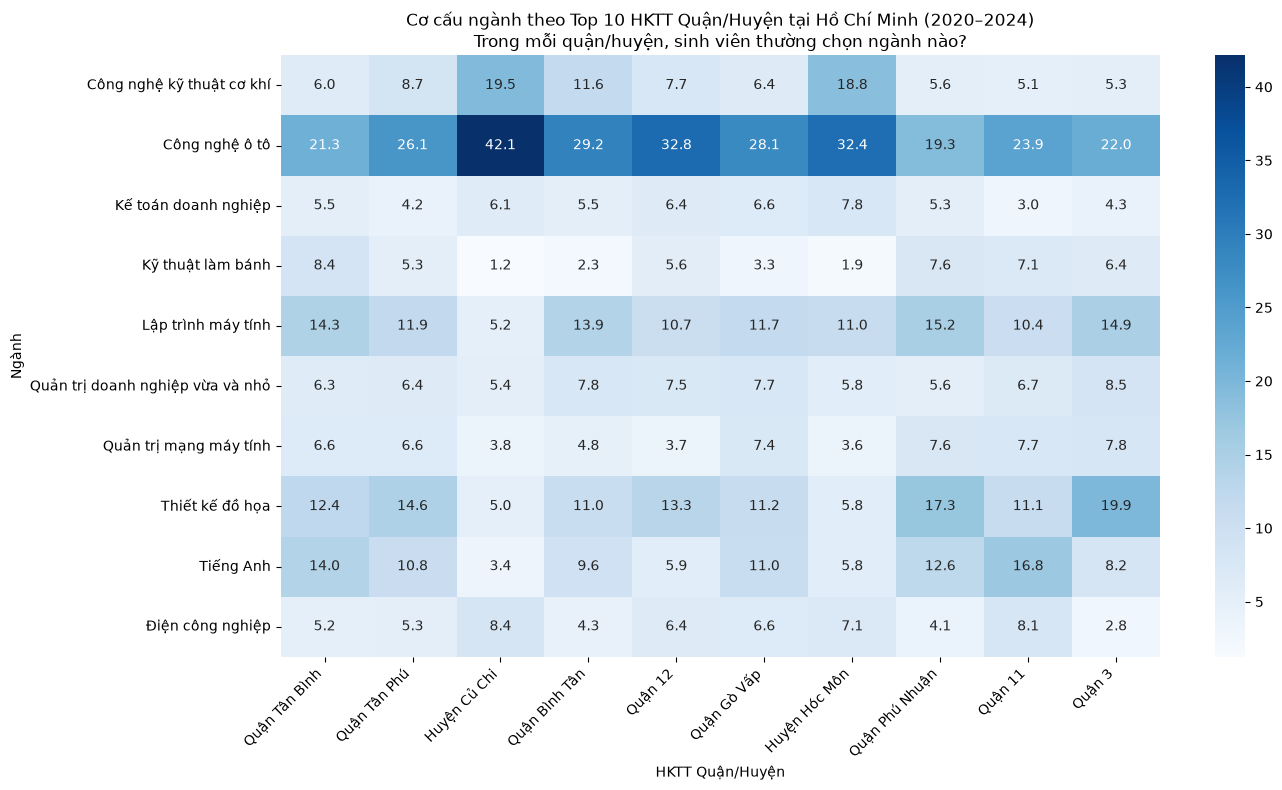

In [56]:
# Chỉ lấy Top 10 quận/huyện theo tổng số SV
top10_district = (
    hcm_district["HKTT_Huyện"]
    .value_counts()
    .head(10)
    .index
)

# Top 10 ngành trong nhóm HCM
top10_major = (
    hcm_district["Ngành"]
    .value_counts()
    .head(10)
    .index
)

temp = hcm_district[
    hcm_district["HKTT_Huyện"].isin(top10_district)
].copy()

# Các ngành ngoài Top 10 gom thành "Các ngành khác"
temp["Nhóm ngành"] = temp["Ngành"].where(
    temp["Ngành"].isin(top10_major)
)

# Quận/Huyện × Ngành
district_major = pd.crosstab(
    temp["HKTT_Huyện"],
    temp["Nhóm ngành"]
)

# % TRONG TỪNG QUẬN/HUYỆN
district_major_pct = (
    district_major
    .div(district_major.sum(axis=1), axis=0)
    * 100
)

# Sắp xếp lại theo Top 10 quận/huyện
district_major_pct = district_major_pct.loc[top10_district]

plt.figure(figsize=(14, 8))

sns.heatmap(
    district_major_pct.T,   # Hoán đổi trục X và Y
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title(
    "Cơ cấu ngành theo Top 10 HKTT Quận/Huyện tại Hồ Chí Minh (2020–2024)\n"
    "Trong mỗi quận/huyện, sinh viên thường chọn ngành nào?"
)

plt.xlabel("HKTT Quận/Huyện")
plt.ylabel("Ngành")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

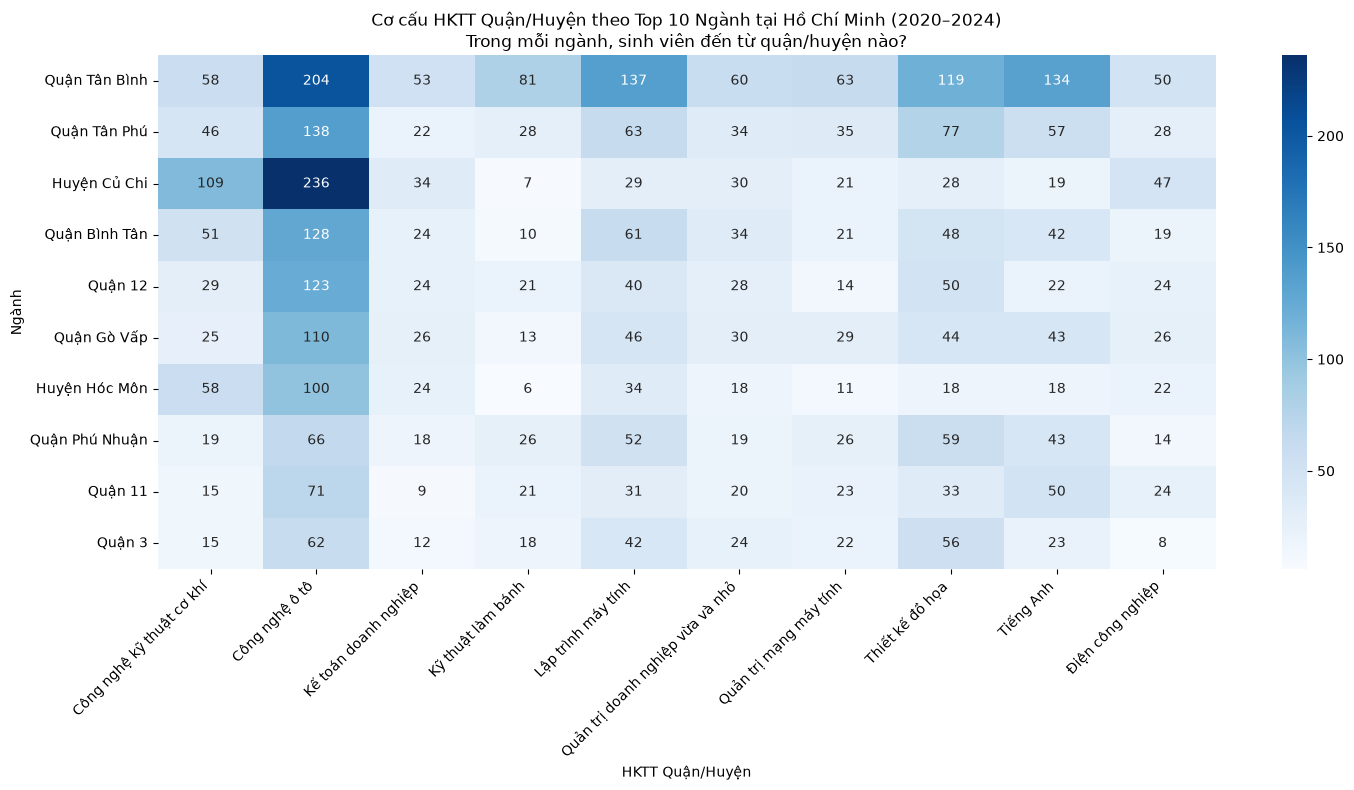

In [62]:
# Chỉ giữ Top 10 ngành
temp = hcm_district[
    hcm_district["Ngành"].isin(top10_major)
].copy()

# Gom các quận/huyện ngoài Top 10 thành "Các quận/huyện khác"
temp["Nhóm quận/huyện"] = temp["HKTT_Huyện"].where(
    temp["HKTT_Huyện"].isin(top10_district)
)

# Ngành × Quận/Huyện
major_district = pd.crosstab(
    temp["Ngành"],
    temp["Nhóm quận/huyện"]
)

# Chuyển sang %
major_district_pct = (
    major_district
    .div(major_district.sum(axis=1), axis=0)
    * 100
)

# Sắp xếp cột
cols =  [
    d for d in top10_district
    if d in major_district_pct.columns
]

major_district_pct = major_district_pct[cols]
major_district_count = major_district[cols]

plt.figure(figsize=(15, 8))

sns.heatmap(
    major_district_count.T,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Cơ cấu HKTT Quận/Huyện theo Top 10 Ngành tại Hồ Chí Minh (2020–2024)\n"
    "Trong mỗi ngành, sinh viên đến từ quận/huyện nào?"
)

plt.xlabel("HKTT Quận/Huyện")
plt.ylabel("Ngành")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

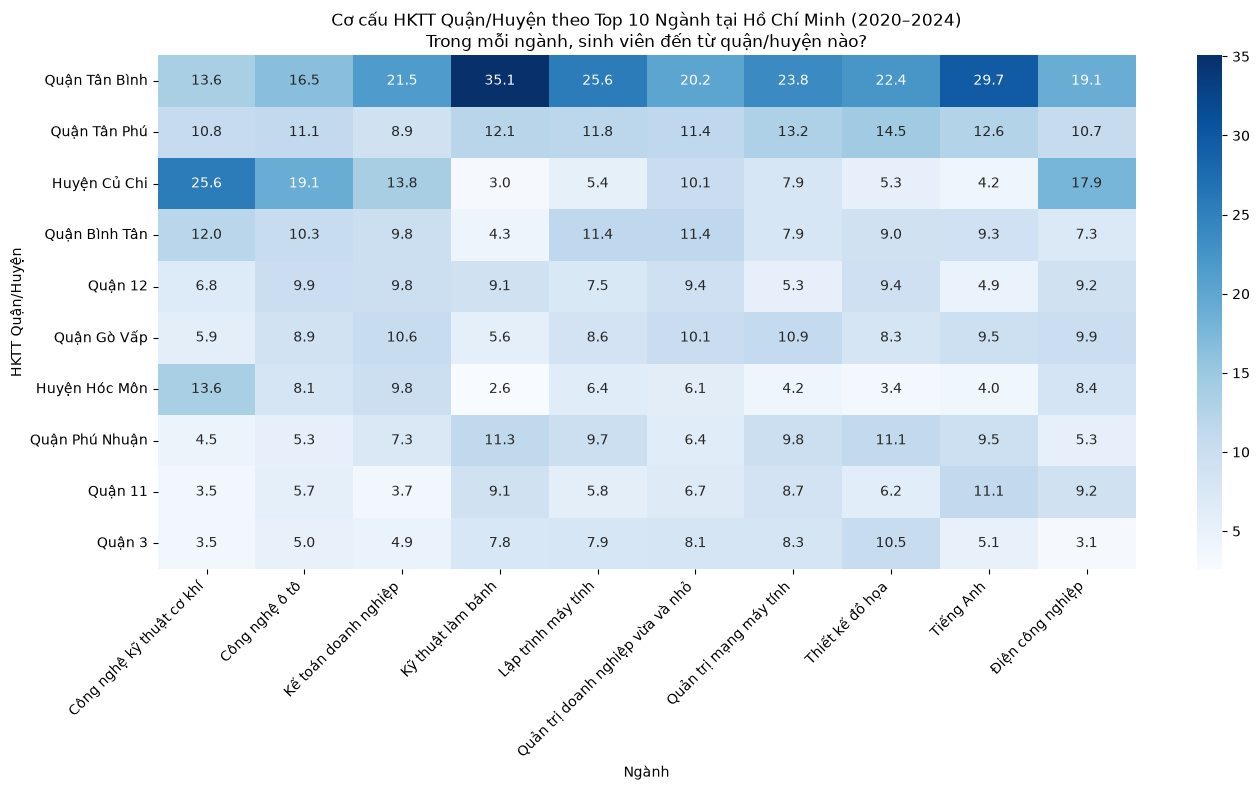

In [63]:
# Chỉ giữ Top 10 ngành
temp = hcm_district[
    hcm_district["Ngành"].isin(top10_major)
].copy()

# Gom các quận/huyện ngoài Top 10 thành "Các quận/huyện khác"
temp["Nhóm quận/huyện"] = temp["HKTT_Huyện"].where(
    temp["HKTT_Huyện"].isin(top10_district)
)

# Ngành × Quận/Huyện
major_district = pd.crosstab(
    temp["Ngành"],
    temp["Nhóm quận/huyện"]
)

# Chuyển sang %
major_district_pct = (
    major_district
    .div(major_district.sum(axis=1), axis=0)
    * 100
)

# Sắp xếp cột
cols =  [
    d for d in top10_district
    if d in major_district_pct.columns
]

major_district_pct = major_district_pct[cols]

plt.figure(figsize=(14, 8))

sns.heatmap(
    major_district_pct.T,   # Hoán đổi trục
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title(
    "Cơ cấu HKTT Quận/Huyện theo Top 10 Ngành tại Hồ Chí Minh (2020–2024)\n"
    "Trong mỗi ngành, sinh viên đến từ quận/huyện nào?"
)

plt.xlabel("Ngành")
plt.ylabel("HKTT Quận/Huyện")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [70]:
# Danh sách đơn vị cấp quận/huyện cũ
old_districts = [
    "Quận 1", "Quận 2", "Quận 3", "Quận 4", "Quận 5",
    "Quận 6", "Quận 7", "Quận 8", "Quận 9", "Quận 10",
    "Quận 11", "Quận 12",
    "Quận Bình Tân", "Quận Bình Thạnh", "Quận Gò Vấp",
    "Quận Phú Nhuận", "Quận Tân Bình", "Quận Tân Phú",
    "Huyện Bình Chánh", "Huyện Cần Giờ", "Huyện Củ Chi",
    "Huyện Hóc Môn", "Huyện Nhà Bè",
    "Thành phố Thủ Đức"
]

hcm_2025 = df_hcm[df_hcm["Khóa học"] == 2025].copy()

valid_2025 = hcm_2025[
    hcm_2025["HKTT_Huyện"].isin(old_districts)
]

print(f"Tổng SV HCM 2025: {len(hcm_2025):,}")
print(f"Có quận/huyện cũ hợp lệ: {len(valid_2025):,}")
print(f"Tỷ lệ sử dụng được: {len(valid_2025)/len(hcm_2025)*100:.1f}%")

Tổng SV HCM 2025: 1,105
Có quận/huyện cũ hợp lệ: 892
Tỷ lệ sử dụng được: 80.7%


In [72]:
hcm_2026 = df_analysis[
    (df_analysis["Khóa học"] == 2026) &
    (df_analysis["Tên tỉnh THPT"] == "Hồ Chí Minh") &
    (df_analysis["HKTT_Tỉnh"] == "Hồ Chí Minh") &
    (df_analysis["HKTT_Huyện"] != "Không xác định")
].copy()

print(f"Tổng SV dùng để phân tích: {len(hcm_2026):,}")
print(f"Số Phường/Xã unique: {hcm_2026['HKTT_Huyện'].nunique()}")

print(
    hcm_2026["HKTT_Huyện"]
    .value_counts()
    .head(30)
    .to_string()
)

Tổng SV dùng để phân tích: 1,264
Số Phường/Xã unique: 150
HKTT_Huyện
Xã Củ Chi                 50
Phường Bảy Hiền         40
Phường Bình Hưng Hòa      32
Xã Đông Thạnh             32
Xã Tân An Hội             28
Phường Tân Hòa           27
Xã Bà Điểm                27
Xã Thái Mỹ                25
Phường Gia Định           25
Phường Phú Nhuận          24
Xã Phú Hòa Đông           23
Phường Đông Hưng Thuận    22
Xã Xuân Thới Sơn          21
Phường Nhiêu Lộc          20
Xã Nhuận Đức              20
Phường Vườn Lài           19
Phường Tân Bình          19
Phường Hòa Bình           19
Xã An Nhơn Tây            18
Phường Bình Trị Đông      18
Phường Tân Phú            18
Phường Cầu Kiệu           17
Phường Bình Thạnh         17
Phường Tân Sơn Nhất      17
Phường Bình Thới          17
Phường Bình Tân           16
Phường An Lạc             16
Phường Phú Thọ Hòa        16
Xã Tân Vĩnh Lộc           15
Phường Phú Định           15


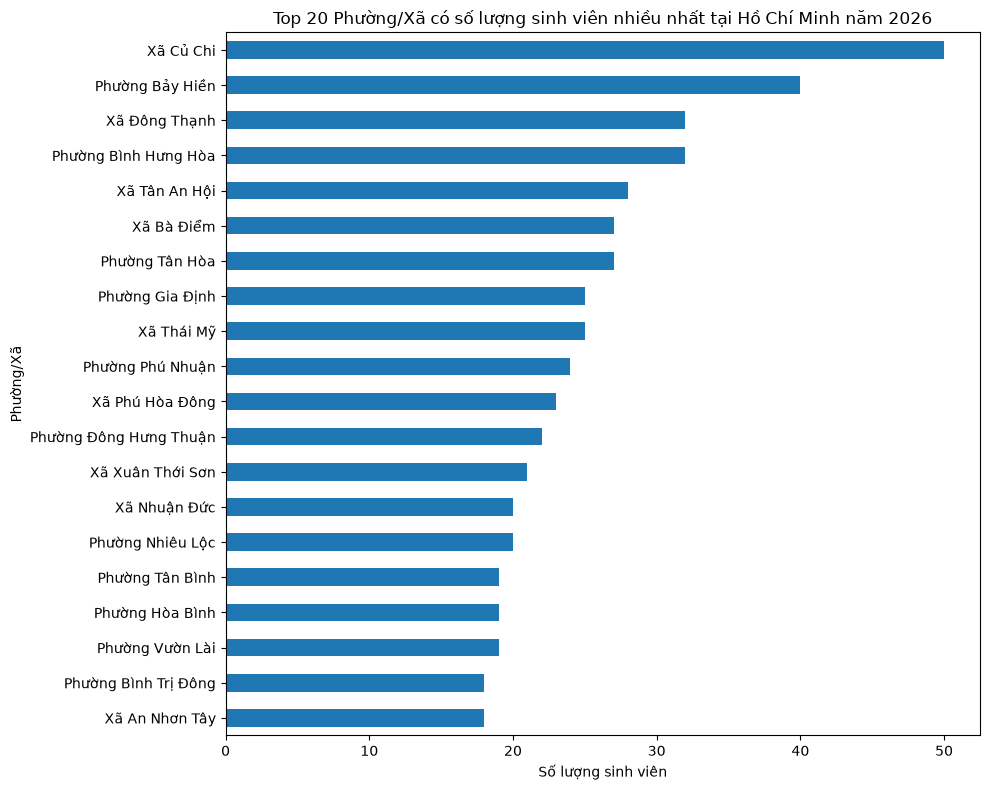

In [73]:
top20_ward = (
    hcm_2026["HKTT_Huyện"]
    .value_counts()
    .head(20)
    .sort_values()
)

plt.figure(figsize=(10, 8))

top20_ward.plot(kind="barh")

plt.title(
    "Top 20 Phường/Xã có số lượng sinh viên nhiều nhất tại Hồ Chí Minh năm 2026"
)
plt.xlabel("Số lượng sinh viên")
plt.ylabel("Phường/Xã")

plt.tight_layout()
plt.show()

In [74]:
ward_summary = (
    hcm_2026["HKTT_Huyện"]
    .value_counts()
    .rename_axis("Phường/Xã")
    .reset_index(name="Số lượng")
)

ward_summary["Tỷ lệ (%)"] = (
    ward_summary["Số lượng"] /
    ward_summary["Số lượng"].sum() * 100
).round(1)

ward_summary.head(20)

,Phường/Xã,Số lượng,Tỷ lệ (%)
0,Xã Củ Chi,50,4.0
1,Phường Bảy Hiền,40,3.2
2,Phường Bình Hưng Hòa,32,2.5
3,Xã Đông Thạnh,32,2.5
4,Xã Tân An Hội,28,2.2
5,Phường Tân Hòa,27,2.1
6,Xã Bà Điểm,27,2.1
7,Xã Thái Mỹ,25,2.0
8,Phường Gia Định,25,2.0
9,Phường Phú Nhuận,24,1.9


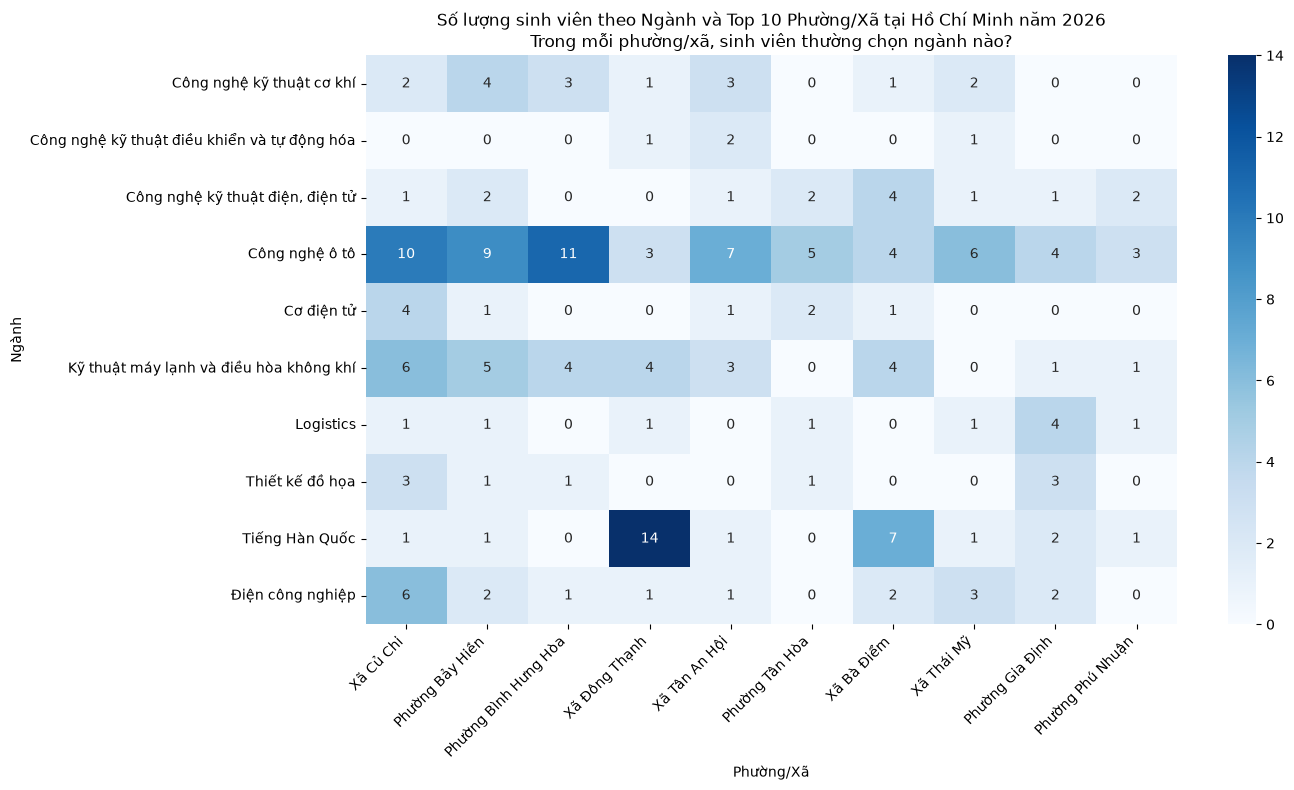

In [75]:
top10_ward = (
    hcm_2026["HKTT_Huyện"]
    .value_counts()
    .head(10)
    .index
)

top10_major_2026 = (
    hcm_2026["Ngành"]
    .value_counts()
    .head(10)
    .index
)

temp = hcm_2026[
    hcm_2026["HKTT_Huyện"].isin(top10_ward) &
    hcm_2026["Ngành"].isin(top10_major_2026)
].copy()

ward_major_count = pd.crosstab(
    temp["Ngành"],
    temp["HKTT_Huyện"]
)

# Sắp xếp theo Top 10 phường/xã
cols = [
    w for w in top10_ward
    if w in ward_major_count.columns
]

ward_major_count = ward_major_count[cols]

plt.figure(figsize=(14, 8))

sns.heatmap(
    ward_major_count,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Số lượng sinh viên theo Ngành và Top 10 Phường/Xã tại Hồ Chí Minh năm 2026\n"
    "Trong mỗi phường/xã, sinh viên thường chọn ngành nào?"
)

plt.xlabel("Phường/Xã")
plt.ylabel("Ngành")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()